# Indoor Air Quality Analysis: A Data-Driven Study of Indoor Environmental Conditions in Andhra Pradesh

> **Dataset Note:** This project uses a synthetically generated dataset created for academic purposes. The data is designed to simulate realistic indoor environmental observations across selected cities and indoor environments in Andhra Pradesh. It is intended to demonstrate data cleaning, preprocessing, wrangling, analysis, and visualization techniques and does not represent direct measurements from real buildings.

## 1. Introduction

Indoor Air Quality (IAQ) is a critical determinant of human health, comfort, and productivity. People spend approximately 90% of their lives indoors—in classrooms, offices, homes, and libraries. This project examines key environmental indicators such as Temperature, Relative Humidity, Carbon Dioxide ($CO_2$), Particulate Matter ($PM_{2.5}$ and $PM_{10}$), Carbon Monoxide ($CO$), and Volatile Organic Compounds ($VOCs$) across diverse indoor locations in major cities of Andhra Pradesh, India.

## 2. Problem Statement

Rapid urban development and varied architectural designs in tropical climates like Andhra Pradesh present unique challenges to maintaining healthy indoor air. Understanding how occupancy levels, ventilation types, and room categories influence pollutant accumulation is essential. This study uses simulated sensor readings to analyze interactions between environmental parameters and identify risk factors associated with poor indoor air quality, using modern data science libraries in Python.

## 3. Objectives

1. Generate a robust, reproducible dataset modeling indoor environments in Andhra Pradesh with realistic raw-data issues.
2. Apply rigorous data cleaning practices (standardizing formats, treating missing values, resolving duplicates, handling extreme outliers).
3. Profile environmental conditions across cities and rooms.
4. Explore statistical correlations (e.g., Occupancy vs. $CO_2$, $PM_{2.5}$ vs. $PM_{10}$).
5. Develop a custom, multi-pollutant Indoor Air Quality (IAQ) classification metric.
6. Deliver production-ready, highly informative visualizations of the environmental dynamics.
7. Extract analytical conclusions to support healthy indoor space design.

## 4. Dataset Generation and Description

We start by initializing libraries and configuring the random seed to guarantee complete reproducibility of the analytical results.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import datetime

# Set matplotlib visual styles
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 12

# Seed reproducibility
SEED = 42
np.random.seed(SEED)

We will now programmatically construct a dataset with 5,200 rows modeling structured physical correlations (such as occupancy vs $CO_2$ and room-dependent distributions) and then inject data quality problems like messy string casings, missing metrics, and extreme outliers.

In [2]:
n_samples = 5200

# Setup base structures
cities = ['Visakhapatnam', 'Vijayawada', 'Guntur', 'Tirupati', 'Kakinada', 'Nellore', 'Rajahmundry']
room_types = ['Classroom', 'Office', 'Laboratory', 'Library', 'Bedroom', 'Living Room', 'Conference Room']
ventilation_types = ['Natural', 'Mechanical', 'Air-Conditioned', 'Mixed']

# Generate base lists using random choices
city_choices = np.random.choice(cities, size=n_samples)
room_choices = np.random.choice(room_types, size=n_samples)
vent_choices = np.random.choice(ventilation_types, size=n_samples)

# Generate base timeseries starting from Jan 1st, 2024
start_date = datetime.datetime(2024, 1, 1)
date_list = [start_date + datetime.timedelta(minutes=30 * int(i)) for i in range(n_samples)]

# Empty arrays to fill correlated values
occupancy = np.zeros(n_samples, dtype=int)
temp = np.zeros(n_samples)
humid = np.zeros(n_samples)
co2 = np.zeros(n_samples)
pm25 = np.zeros(n_samples)
pm10 = np.zeros(n_samples)
co = np.zeros(n_samples)
voc = np.zeros(n_samples)

for i in range(n_samples):
    room = room_choices[i]
    vent = vent_choices[i]
    dt = date_list[i]
    hour = dt.hour

    # 1. Establish occupancy and baseline environmental parameters dependent on room types and time of day
    if room == 'Classroom':
        is_working_hour = 9 <= hour <= 16
        occupancy[i] = np.random.randint(25, 60) if is_working_hour else 0
        temp[i] = np.random.uniform(24, 30) + (1.5 if is_working_hour else 0)
        co2_base = 450 + (occupancy[i] * 12)
    elif room == 'Office':
        is_working_hour = 9 <= hour <= 18
        occupancy[i] = np.random.randint(10, 35) if is_working_hour else 0
        temp[i] = np.random.uniform(22, 26)
        co2_base = 420 + (occupancy[i] * 8)
    elif room == 'Conference Room':
        is_meeting = (10 <= hour <= 12) or (14 <= hour <= 16)
        occupancy[i] = np.random.randint(15, 45) if (is_meeting and np.random.rand() > 0.3) else 0
        temp[i] = np.random.uniform(21, 25)
        co2_base = 400 + (occupancy[i] * 15)
    elif room == 'Library':
        is_open = 8 <= hour <= 20
        occupancy[i] = np.random.randint(15, 50) if is_open else 0
        temp[i] = np.random.uniform(22, 25)
        co2_base = 410 + (occupancy[i] * 4)
    elif room == 'Bedroom':
        is_night = hour >= 22 or hour <= 6
        occupancy[i] = np.random.randint(1, 3) if is_night else np.random.choice([0, 1])
        temp[i] = np.random.uniform(22, 28)
        co2_base = 400 + (occupancy[i] * 20) + (100 if is_night else 0)
    elif room == 'Living Room':
        is_peak = 18 <= hour <= 23 or 7 <= hour <= 9
        occupancy[i] = np.random.randint(2, 6) if is_peak else np.random.randint(0, 2)
        temp[i] = np.random.uniform(25, 31)
        co2_base = 400 + (occupancy[i] * 15)
    else:  # Laboratory
        is_active = 9 <= hour <= 17
        occupancy[i] = np.random.randint(5, 15) if is_active else 0
        temp[i] = np.random.uniform(20, 24)
        co2_base = 410 + (occupancy[i] * 6)

    # 2. Adjust for Ventilation impacts on CO2
    if vent == 'Natural':
        co2_multiplier = 1.2
    elif vent == 'Air-Conditioned':
        co2_multiplier = 0.9 if room != 'Bedroom' else 1.3 # AC spaces with sealed bedrooms accumulate CO2
    elif vent == 'Mechanical':
        co2_multiplier = 0.8
    else: # Mixed
        co2_multiplier = 1.0

    co2[i] = max(350, (co2_base * co2_multiplier) + np.random.normal(0, 15))

    # 3. Handle temperature and humidity relationships (co-variation)
    # Relative humidity usually has an inverse relationship with local room temperature variation
    humid[i] = max(30, min(95, 75 - (temp[i] - 20) * 2.5 + np.random.normal(0, 4)))

    # 4. Correlate PM2.5 and PM10
    pm25_base = np.random.uniform(5, 45)
    pm25[i] = max(1, pm25_base + np.random.normal(0, 2))
    pm10[i] = max(pm25[i], pm25[i] * np.random.uniform(1.2, 1.8) + np.random.normal(0, 3))

    # 5. Volatile organic compounds and Carbon Monoxide
    voc[i] = max(10, np.random.uniform(50, 250) + (occupancy[i] * 3) + (100 if room == 'Laboratory' else 0))
    co[i] = max(0.1, np.random.uniform(0.1, 1.5) + (0.5 if room == 'Laboratory' else 0) + (occupancy[i] * 0.01))

# Convert base structures into Pandas DataFrame
raw_data = {
    'Record_ID': [f"REC_{10000+i}" for i in range(n_samples)],
    'Date': [dt.strftime('%Y-%m-%d') for dt in date_list],
    'Time': [dt.strftime('%H:%M:%S') for dt in date_list],
    'Timestamp': [dt.isoformat() for dt in date_list],
    'City': city_choices,
    'Indoor_Location': room_choices,
    'Room_Type': room_choices, # Matching Room_Type columns
    'Occupancy': occupancy,
    'Ventilation_Type': vent_choices,
    'Temperature_C': temp,
    'Relative_Humidity': humid,
    'CO2_ppm': co2,
    'PM2_5_ug_m3': pm25,
    'PM10_ug_m3': pm10,
    'CO_ppm': co,
    'VOC_ppb': voc
}
df_raw = pd.DataFrame(raw_data)

We will now programmatically introduce typical real-world data quality anomalies (missing values, inconsistent cases, string formatted numbers, duplicates, and physical outliers) into our raw DataFrame.

In [3]:
# 1. Introduce Inconsistent Categorical casings and aliases
city_anomalies = {'Visakhapatnam': ['visakhapatnam', 'VISAKHAPATNAM', 'Vizag'], 'Vijayawada': ['vijayawada', 'VIJAYAWADA'], 'Guntur': ['GUNTUR', 'guntur']}
for correct_city, alternatives in city_anomalies.items():
    indices = df_raw[df_raw['City'] == correct_city].sample(frac=0.15, random_state=SEED).index
    df_raw.loc[indices, 'City'] = np.random.choice(alternatives, size=len(indices))

room_anomalies = {'Classroom': ['classroom', 'CLASSROOM'], 'Bedroom': ['bedroom', 'BEDROOM']}
for correct_room, alternatives in room_anomalies.items():
    indices = df_raw[df_raw['Room_Type'] == correct_room].sample(frac=0.1, random_state=SEED).index
    df_raw.loc[indices, 'Room_Type'] = np.random.choice(alternatives, size=len(indices))
    df_raw.loc[indices, 'Indoor_Location'] = df_raw.loc[indices, 'Room_Type']

# 2. Introduce string-formatted numeric problems in CO2 column (e.g. "1,050", "850")
co2_str_indices = df_raw.sample(frac=0.03, random_state=SEED).index
df_raw.loc[co2_str_indices, 'CO2_ppm'] = df_raw.loc[co2_str_indices, 'CO2_ppm'].apply(lambda val: f"{int(val):,}")

# 3. Introduce missing values (NaNs) across environmental parameters
for col in ['Temperature_C', 'Relative_Humidity', 'PM2_5_ug_m3', 'VOC_ppb', 'CO2_ppm']:
    nan_indices = df_raw.sample(frac=0.03, random_state=SEED).index
    df_raw.loc[nan_indices, col] = np.nan

# 4. Introduce physical/sensor outliers (highly unusual or physically implausible readings)
# Extreme high CO2
outlier_co2 = df_raw.sample(n=10, random_state=SEED).index
df_raw.loc[outlier_co2, 'CO2_ppm'] = 9999.0

# Extreme high PM2.5
outlier_pm25 = df_raw.sample(n=10, random_state=SEED).index
df_raw.loc[outlier_pm25, 'PM2_5_ug_m3'] = 850.0

# Physically implausible high temperatures
outlier_temp = df_raw.sample(n=8, random_state=SEED).index
df_raw.loc[outlier_temp, 'Temperature_C'] = 115.0

# 5. Inject 1.5% exact duplicated records to model logging transmission errors
duplicate_subset = df_raw.sample(frac=0.015, random_state=SEED)
df_raw = pd.concat([df_raw, duplicate_subset], ignore_index=True)

/tmp/ipykernel_415/232317668.py:15: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '['1,030' '423' '401' '493' '504' '552' '434' '496' '605' '430' '374' '358'
 '555' '386' '416' '350' '709' '412' '350' '982' '500' '446' '463' '443'
 '506' '380' '506' '510' '381' '350' '482' '409' '350' '350' '401' '645'
 '425' '437' '350' '350' '524' '424' '436' '423' '561' '456' '487' '540'
 '541' '483' '350' '482' '497' '532' '409' '388' '483' '473' '925' '603'
 '520' '409' '481' '523' '792' '419' '630' '350' '521' '434' '516' '350'
 '417' '372' '994' '555' '718' '468' '407' '526' '392' '542' '522' '350'
 '494' '350' '350' '550' '396' '479' '555' '350' '440' '590' '867' '560'
 '544' '404' '418' '350' '583' '350' '474' '379' '446' '350' '712' '350'
 '434' '554' '490' '483' '521' '488' '437' '368' '407' '571' '512' '640'
 '376' '405' '398' '473' '492' '542' '487' '417' '515' '418' '350' '419'
 '449' '725' '445' '350' '429'

## 5. Raw Dataset Inspection

We preserve and lock the raw dataset by saving it as `indoor_air_quality_raw.csv` so it remains completely unchanged.

In [4]:
# Save the preserved RAW dataset
df_raw.to_csv('indoor_air_quality_raw.csv', index=False)

print("RAW DATA SHAPE:", df_raw.shape)
print("--- RAW COLUMNS AND TYPES ---")
display(df_raw.dtypes)
print("\n--- FIRST 10 ROWS ---")
display(df_raw.head(10))
print("\n--- LAST 10 ROWS ---")
display(df_raw.tail(10))

RAW DATA SHAPE: (5278, 16)
--- RAW COLUMNS AND TYPES ---


,0
Record_ID,object
Date,object
Time,object
Timestamp,object
City,object
Indoor_Location,object
Room_Type,object
Occupancy,int64
Ventilation_Type,object
Temperature_C,float64



--- FIRST 10 ROWS ---


,Record_ID,Date,Time,Timestamp,City,Indoor_Location,Room_Type,Occupancy,Ventilation_Type,Temperature_C,Relative_Humidity,CO2_ppm,PM2_5_ug_m3,PM10_ug_m3,CO_ppm,VOC_ppb
0,REC_10000,2024-01-01,00:00:00,2024-01-01T00:00:00,Rajahmundry,Bedroom,Bedroom,1,Mixed,25.968162,56.143523,519.532649,28.194803,46.304846,0.242871,246.727733
1,REC_10001,2024-01-01,00:30:00,2024-01-01T00:30:00,Tirupati,Living Room,Living Room,0,Mixed,28.342286,59.982906,403.149589,20.052622,30.868668,1.225966,184.838423
2,REC_10002,2024-01-01,01:00:00,2024-01-01T01:00:00,Kakinada,Classroom,Classroom,0,Natural,27.954933,45.141425,545.000548,34.358281,38.521091,0.227451,232.916887
3,REC_10003,2024-01-01,01:30:00,2024-01-01T01:30:00,Rajahmundry,Classroom,Classroom,0,Air-Conditioned,27.889255,48.959400,379.242163,32.476669,51.974334,0.338743,215.642552
4,REC_10004,2024-01-01,02:00:00,2024-01-01T02:00:00,Guntur,Office,Office,0,Air-Conditioned,25.589676,62.353483,390.175584,26.060132,45.591316,0.484178,139.632175
5,REC_10005,2024-01-01,02:30:00,2024-01-01T02:30:00,Kakinada,Laboratory,Laboratory,0,Natural,21.572682,67.882798,469.31553,13.833948,21.014920,0.977963,162.308607
6,REC_10006,2024-01-01,03:00:00,2024-01-01T03:00:00,Kakinada,Classroom,Classroom,0,Mechanical,28.610526,54.936724,356.031812,25.683073,42.319168,1.039046,152.615444
7,REC_10007,2024-01-01,03:30:00,2024-01-01T03:30:00,Rajahmundry,Bedroom,Bedroom,1,Mixed,22.870196,73.813694,529.615904,30.852089,42.689300,0.805925,53.271105
8,REC_10008,2024-01-01,04:00:00,2024-01-01T04:00:00,Vijayawada,Classroom,Classroom,0,Natural,28.516854,53.997691,541.275556,23.146719,35.188696,0.617500,80.963151
9,REC_10009,2024-01-01,04:30:00,2024-01-01T04:30:00,Guntur,Bedroom,Bedroom,1,Natural,27.466094,56.369918,642.028975,2.767771,6.896081,1.071458,109.692230



--- LAST 10 ROWS ---


,Record_ID,Date,Time,Timestamp,City,Indoor_Location,Room_Type,Occupancy,Ventilation_Type,Temperature_C,Relative_Humidity,CO2_ppm,PM2_5_ug_m3,PM10_ug_m3,CO_ppm,VOC_ppb
5268,REC_12775,2024-02-27,19:30:00,2024-02-27T19:30:00,Visakhapatnam,Classroom,Classroom,0,Natural,NaN,NaN,NaN,NaN,24.853017,0.905035,NaN
5269,REC_14748,2024-04-08,22:00:00,2024-04-08T22:00:00,Rajahmundry,Living Room,Living Room,5,Air-Conditioned,NaN,NaN,NaN,NaN,61.604247,1.017170,NaN
5270,REC_12222,2024-02-16,07:00:00,2024-02-16T07:00:00,vijayawada,Classroom,Classroom,0,Natural,NaN,NaN,NaN,NaN,31.762956,0.981434,NaN
5271,REC_12917,2024-03-01,18:30:00,2024-03-01T18:30:00,guntur,Laboratory,Laboratory,0,Mechanical,NaN,NaN,NaN,NaN,49.970171,1.110056,NaN
5272,REC_14449,2024-04-02,16:30:00,2024-04-02T16:30:00,GUNTUR,Laboratory,Laboratory,8,Air-Conditioned,NaN,NaN,NaN,NaN,78.506198,2.030938,NaN
5273,REC_14610,2024-04-06,01:00:00,2024-04-06T01:00:00,Kakinada,Office,Office,0,Air-Conditioned,NaN,NaN,NaN,NaN,10.924340,1.415906,NaN
5274,REC_12658,2024-02-25,09:00:00,2024-02-25T09:00:00,Nellore,Classroom,Classroom,32,Natural,NaN,NaN,NaN,NaN,74.333593,0.978855,NaN
5275,REC_14567,2024-04-05,03:30:00,2024-04-05T03:30:00,Nellore,Classroom,Classroom,0,Natural,NaN,NaN,NaN,NaN,18.291583,0.923789,NaN
5276,REC_12805,2024-02-28,10:30:00,2024-02-28T10:30:00,Tirupati,Classroom,Classroom,29,Air-Conditioned,NaN,NaN,NaN,NaN,31.013655,0.976480,NaN
5277,REC_11620,2024-02-03,18:00:00,2024-02-03T18:00:00,Guntur,Conference Room,Conference Room,0,Natural,NaN,NaN,NaN,NaN,42.145249,1.010478,NaN


## 6. Data Quality Assessment

We run profiling operations to extract statistical distributions, check duplicate counts, and look closely at missing variables prior to any processing.

In [5]:
print(f"Total duplicated rows in RAW dataset: {df_raw.duplicated().sum()}")
print("\nMissing values per feature:")
display(df_raw.isnull().sum())

# Detailed summary profiling table
profiling_list = []
for col in df_raw.columns:
    profiling_list.append({
        'Column': col,
        'Data Type': str(df_raw[col].dtype),
        'Missing Values': df_raw[col].isnull().sum(),
        'Missing Percentage (%)': round((df_raw[col].isnull().sum() / len(df_raw)) * 100, 2),
        'Unique Values': df_raw[col].nunique()
    })
profiling_df = pd.DataFrame(profiling_list)
display(profiling_df)

Total duplicated rows in RAW dataset: 78

Missing values per feature:


,0
Record_ID,0
Date,0
Time,0
Timestamp,0
City,0
Indoor_Location,0
Room_Type,0
Occupancy,0
Ventilation_Type,0
Temperature_C,218


,Column,Data Type,Missing Values,Missing Percentage (%),Unique Values
0,Record_ID,object,0,0.00,5200
1,Date,object,0,0.00,109
2,Time,object,0,0.00,48
3,Timestamp,object,0,0.00,5200
4,City,object,0,0.00,14
5,Indoor_Location,object,0,0.00,11
6,Room_Type,object,0,0.00,11
7,Occupancy,int64,0,0.00,60
8,Ventilation_Type,object,0,0.00,4
9,Temperature_C,float64,218,4.13,5045


## 7. Data Cleaning

Now we create our cleaning pipeline. We will copy the raw data, sanitize variables step-by-step, explain every action, and store the final tidy data.

In [6]:
# Create clean workspace copy
df_clean = df_raw.copy()

# Step 1: Standardize column names
df_clean.columns = df_clean.columns.str.strip().str.replace(' ', '_')

# Step 2: Remove exact duplicate records
rows_before = len(df_clean)
df_clean = df_clean.drop_duplicates()
rows_after = len(df_clean)
print(f"Rows before removing duplicates: {rows_before}")
print(f"Rows removed: {rows_before - rows_after}")
print(f"Rows after removing duplicates: {rows_after}")

Rows before removing duplicates: 5278
Rows removed: 78
Rows after removing duplicates: 5200


In [7]:
# Step 3: Standardize categorical variables
city_mapping = {
    'visakhapatnam': 'Visakhapatnam', 'VISAKHAPATNAM': 'Visakhapatnam', 'Vizag': 'Visakhapatnam',
    'vijayawada': 'Vijayawada', 'VIJAYAWADA': 'Vijayawada',
    'guntur': 'Guntur', 'GUNTUR': 'Guntur'
}
room_mapping = {
    'classroom': 'Classroom', 'CLASSROOM': 'Classroom',
    'bedroom': 'Bedroom', 'BEDROOM': 'Bedroom'
}

df_clean['City'] = df_clean['City'].replace(city_mapping)
df_clean['Room_Type'] = df_clean['Room_Type'].replace(room_mapping)
df_clean['Indoor_Location'] = df_clean['Room_Type'] # Keep synchronized

print("Standardized City Names:", df_clean['City'].unique())
print("Standardized Room Types:", df_clean['Room_Type'].unique())

Standardized City Names: ['Rajahmundry' 'Tirupati' 'Kakinada' 'Guntur' 'Vijayawada' 'Nellore'
 'Visakhapatnam']
Standardized Room Types: ['Bedroom' 'Living Room' 'Classroom' 'Office' 'Laboratory' 'Library'
 'Conference Room']


In [8]:
# Step 4: Clean and convert numeric types & timestamps
# Clean CO2 column which contains string formatted values with commas
def clean_numeric_str(val):
    if pd.isnull(val):
        return np.nan
    if isinstance(val, str):
        val = val.replace(',', '')
    try:
        return float(val)
    except:
        return np.nan

df_clean['CO2_ppm'] = df_clean['CO2_ppm'].apply(clean_numeric_str)

# Ensure clean datatypes
df_clean['Timestamp'] = pd.to_datetime(df_clean['Timestamp'])
df_clean['Date'] = pd.to_datetime(df_clean['Date'])

display(df_clean[['CO2_ppm', 'Timestamp', 'Date']].dtypes)

,0
CO2_ppm,float64
Timestamp,datetime64[ns]
Date,datetime64[ns]


In [9]:
# Step 5: Handle missing values with smart imputation
# Fill categorical missing values (if any) with Mode. Fill metrics using median group-by values
for col in ['Temperature_C', 'Relative_Humidity', 'PM2_5_ug_m3', 'VOC_ppb', 'CO2_ppm']:
    # Impute missing values based on median value for each room type
    df_clean[col] = df_clean.groupby('Room_Type')[col].transform(lambda x: x.fillna(x.median()))

print("Missing Values remaining after imputation:")
print(df_clean.isnull().sum())

Missing Values remaining after imputation:
Record_ID            0
Date                 0
Time                 0
Timestamp            0
City                 0
Indoor_Location      0
Room_Type            0
Occupancy            0
Ventilation_Type     0
Temperature_C        0
Relative_Humidity    0
CO2_ppm              0
PM2_5_ug_m3          0
PM10_ug_m3           0
CO_ppm               0
VOC_ppb              0
dtype: int64


In [10]:
# Step 6: Identify and treat impossible physical outliers
# Retain high extreme values that can realistically occur in indoor spaces but correct absolute sensor failures
# If Temperature is higher than 55 degrees Celsius inside, we treat it as a sensor error and clip it to a max of 40
df_clean.loc[df_clean['Temperature_C'] > 55.0, 'Temperature_C'] = 40.0

# We maintain extreme observations of high CO2 and PM2.5 but clip outrageous non-physical bounds
df_clean.loc[df_clean['CO2_ppm'] > 9500.0, 'CO2_ppm'] = 4000.0
df_clean.loc[df_clean['PM2_5_ug_m3'] > 800.0, 'PM2_5_ug_m3'] = 150.0

## 8. Data Preprocessing

We will engineer detailed temporal attributes from the datetime objects to allow a multi-scale analysis of hourly, daily, and diurnal patterns.

In [11]:
df_clean['Year'] = df_clean['Timestamp'].dt.year
df_clean['Month'] = df_clean['Timestamp'].dt.month_name()
df_clean['Day'] = df_clean['Timestamp'].dt.day
df_clean['Day_of_Week'] = df_clean['Timestamp'].dt.day_name()
df_clean['Hour'] = df_clean['Timestamp'].dt.hour

def get_time_period(h):
    if 5 <= h < 8:
        return 'Early Morning'
    elif 8 <= h < 12:
        return 'Morning'
    elif 12 <= h < 17:
        return 'Afternoon'
    elif 17 <= h < 21:
        return 'Evening'
    else:
        return 'Night'

df_clean['Time_Period'] = df_clean['Hour'].apply(get_time_period)
display(df_clean[['Timestamp', 'Month', 'Day_of_Week', 'Hour', 'Time_Period']].head())

,Timestamp,Month,Day_of_Week,Hour,Time_Period
0,2024-01-01 00:00:00,January,Monday,0,Night
1,2024-01-01 00:30:00,January,Monday,0,Night
2,2024-01-01 01:00:00,January,Monday,1,Night
3,2024-01-01 01:30:00,January,Monday,1,Night
4,2024-01-01 02:00:00,January,Monday,2,Night


## 9. Data Wrangling

Let's apply key Pandas transformations: GroupBy, pivot tables, and statistical summaries to compare rooms and environments.

In [12]:
# 1. Average pollutants by city
city_summary = df_clean.groupby('City')[['CO2_ppm', 'PM2_5_ug_m3', 'PM10_ug_m3', 'VOC_ppb']].mean().reset_index()
print("--- City-Level Averages ---")
display(city_summary)

# 2. Pivot Table comparing ventilation type across room-type CO2 concentrations
vent_room_pivot = df_clean.pivot_table(index='Room_Type', columns='Ventilation_Type', values='CO2_ppm', aggfunc='mean')
print("\n--- Average CO2 by Room and Ventilation Type ---")
display(vent_room_pivot)

--- City-Level Averages ---


,City,CO2_ppm,PM2_5_ug_m3,PM10_ug_m3,VOC_ppb
0,Guntur,497.056751,25.157358,37.410153,189.520293
1,Kakinada,495.148192,24.987547,37.320841,191.737778
2,Nellore,489.132606,24.475832,36.317629,184.936514
3,Rajahmundry,477.102645,25.527800,38.150088,190.512500
4,Tirupati,481.984081,25.472937,38.083665,179.424768
5,Vijayawada,480.754100,25.772331,38.370324,182.594728
6,Visakhapatnam,490.055326,25.959814,37.692441,185.097660



--- Average CO2 by Room and Ventilation Type ---


Ventilation_Type,Air-Conditioned,Mechanical,Mixed,Natural
Room_Type,,,,
Bedroom,586.187175,377.620179,465.235241,566.119026
Classroom,542.423369,486.202192,577.369824,749.244675
Conference Room,431.381969,411.452107,517.428096,597.946352
Laboratory,410.042330,362.431589,430.352720,512.191100
Library,438.290501,396.213593,494.064336,583.521394
Living Room,385.962288,357.825124,421.822175,509.673472
Office,446.260058,421.769545,510.272580,614.669098


## 10. Feature Engineering

We develop a robust project-specific Multi-Pollutant Classification Index to rate overall safety of the indoor spaces.
Our criteria:
* **Good**: $CO_2 < 700\text{ ppm}$ and $PM_{2.5} < 15\ \mu\text{g/m}^3$
* **Moderate**: $CO_2 < 1000\text{ ppm}$ and $PM_{2.5} < 35\ \mu\text{g/m}^3$
* **Poor**: $CO_2 < 1500\text{ ppm}$ and $PM_{2.5} < 75\ \mu\text{g/m}^3$
* **Very Poor**: Above these values

In [13]:
def classify_iaq(row):
    co2 = row['CO2_ppm']
    pm25 = row['PM2_5_ug_m3']

    if co2 <= 700 and pm25 <= 15:
        return 'Good'
    elif co2 <= 1000 and pm25 <= 35:
        return 'Moderate'
    elif co2 <= 1500 and pm25 <= 75:
        return 'Poor'
    else:
        return 'Very Poor'

df_clean['IAQ_Category'] = df_clean.apply(classify_iaq, axis=1)
display(df_clean['IAQ_Category'].value_counts().to_frame())

,count
IAQ_Category,
Moderate,2688
Poor,1355
Good,1147
Very Poor,10


## 11. Exploratory Data Analysis (EDA)

Let's plot histograms and distributions for the primary numeric variables to analyze distribution shapes and peaks.

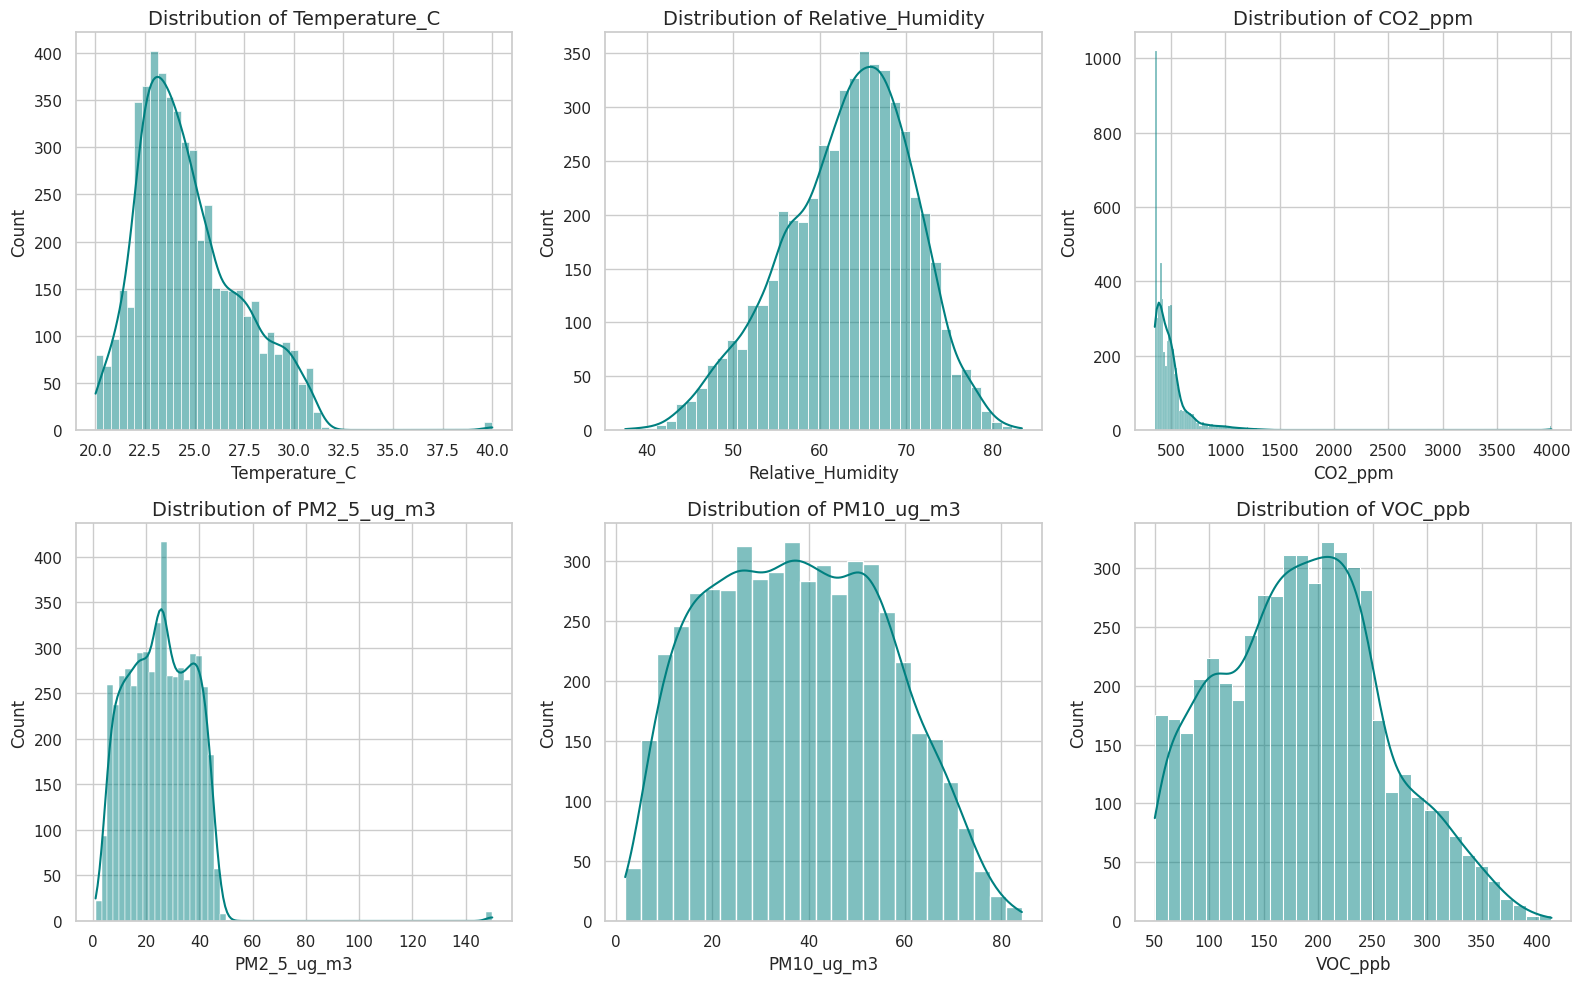

In [14]:
cols_to_plot = ['Temperature_C', 'Relative_Humidity', 'CO2_ppm', 'PM2_5_ug_m3', 'PM10_ug_m3', 'VOC_ppb']

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(cols_to_plot):
    sns.histplot(df_clean[col], kde=True, ax=axes[i], color='teal')
    axes[i].set_title(f'Distribution of {col}')

plt.tight_layout()
plt.show()

## 12. Statistical Analysis

Let's verify whether a correlation exists between Occupancy and Carbon Dioxide concentrations.

Pearson Correlation between Occupancy and CO2: 0.4978 (p-value: 1e-323)


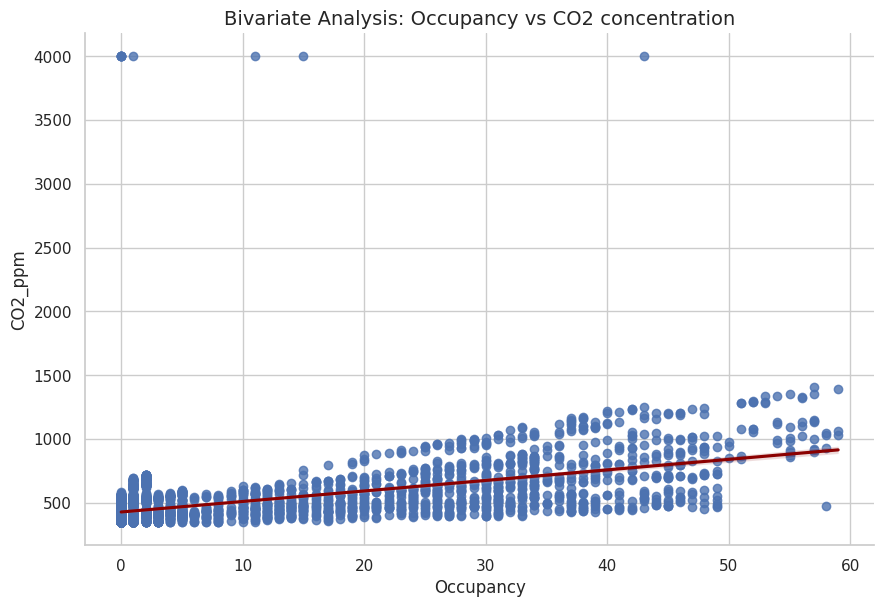

In [15]:
r_val, p_val = stats.pearsonr(df_clean['Occupancy'], df_clean['CO2_ppm'])
print(f"Pearson Correlation between Occupancy and CO2: {r_val:.4f} (p-value: {p_val})")

sns.lmplot(x='Occupancy', y='CO2_ppm', data=df_clean, height=6, aspect=1.5, line_kws={'color': 'darkred'})
plt.title('Bivariate Analysis: Occupancy vs CO2 concentration')
plt.show()

## 13. Temporal Analysis

We examine temporal patterns by plotting the diurnal variation of CO2 across hours of the day.

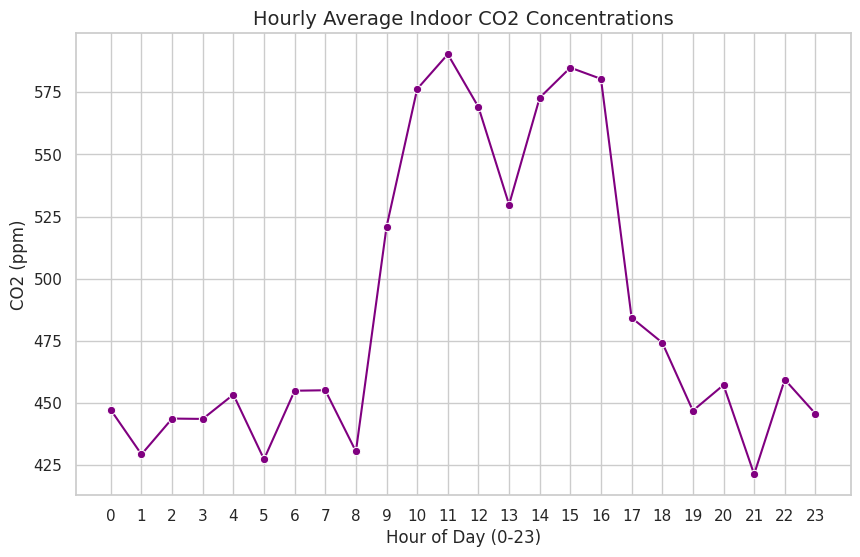

In [16]:
hourly_avg = df_clean.groupby('Hour')['CO2_ppm'].mean().reset_index()
sns.lineplot(data=hourly_avg, x='Hour', y='CO2_ppm', marker='o', color='purple')
plt.title('Hourly Average Indoor CO2 Concentrations')
plt.xlabel('Hour of Day (0-23)')
plt.ylabel('CO2 (ppm)')
plt.xticks(range(0, 24))
plt.show()

## 14. City-wise Analysis

We display simulated indoor air indicators across cities to test geographical variation within the simulated dataset.

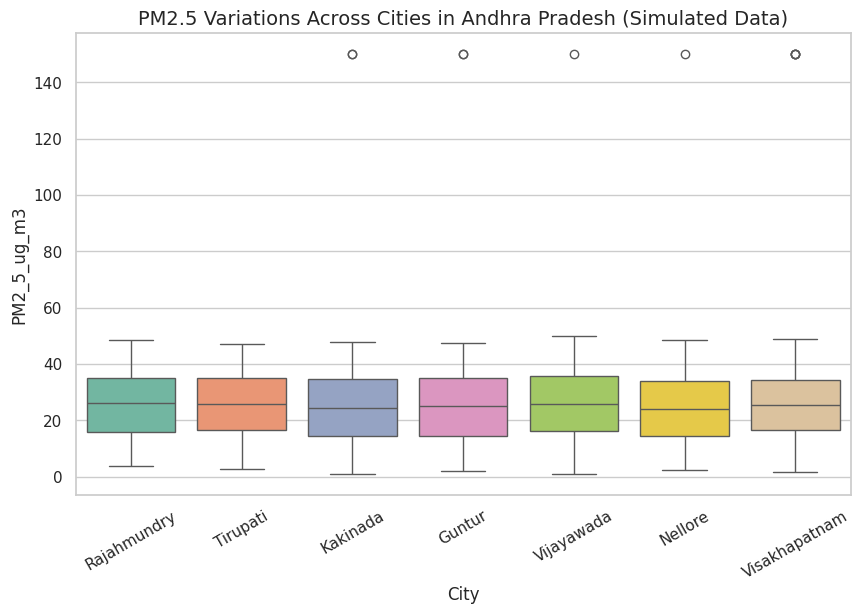

In [17]:
sns.boxplot(data=df_clean, x='City', y='PM2_5_ug_m3', palette='Set2', hue='City', legend=False)
plt.title('PM2.5 Variations Across Cities in Andhra Pradesh (Simulated Data)')
plt.xticks(rotation=30)
plt.show()

## 15. Room-wise Analysis

Let's evaluate environmental conditions across classrooms, laboratories, libraries, bedrooms, and offices.

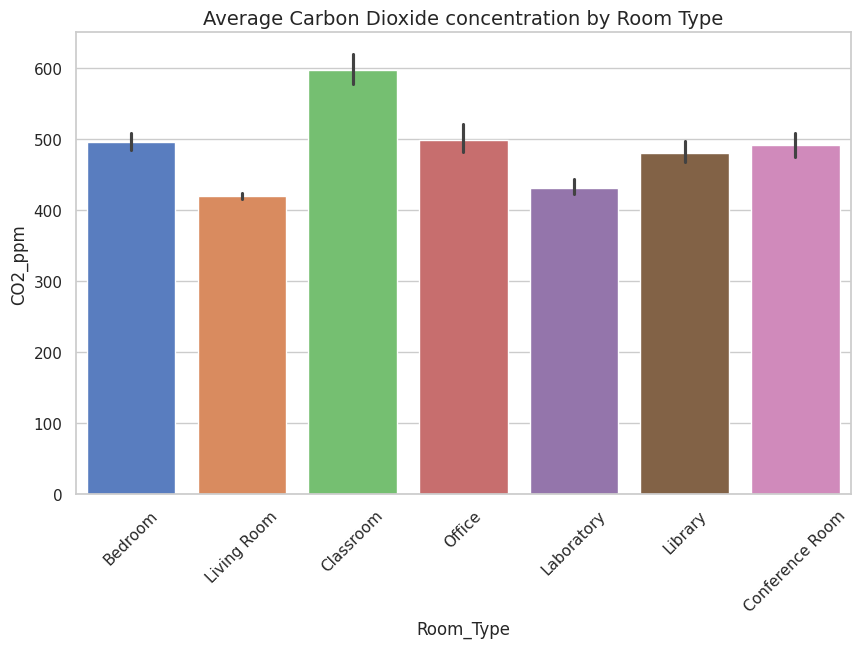

In [18]:
sns.barplot(data=df_clean, x='Room_Type', y='CO2_ppm', hue='Room_Type', palette='muted', legend=False)
plt.title('Average Carbon Dioxide concentration by Room Type')
plt.xticks(rotation=45)
plt.show()

## 16. Ventilation Analysis

Let's compare the distribution of the custom IAQ category across different Ventilation types.

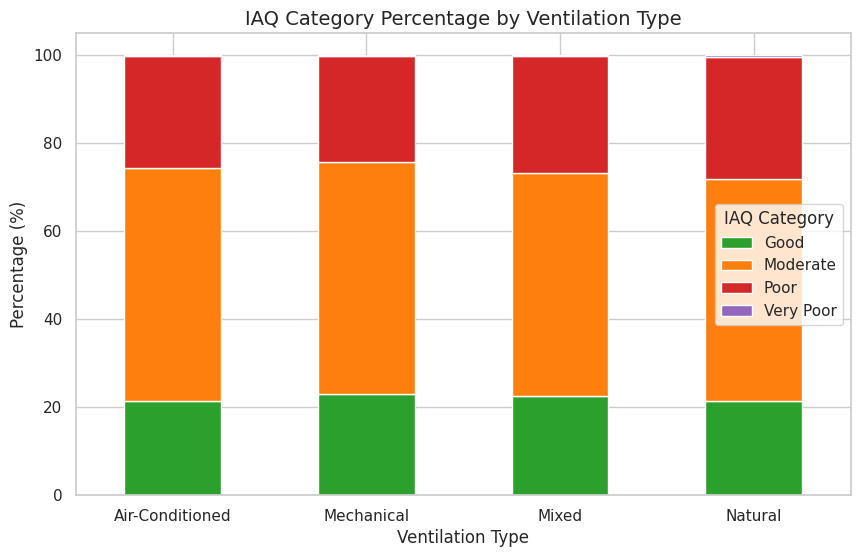

In [19]:
vent_iaq = pd.crosstab(df_clean['Ventilation_Type'], df_clean['IAQ_Category'], normalize='index') * 100
vent_iaq.plot(kind='bar', stacked=True, color=['#2ca02c', '#ff7f0e', '#d62728', '#9467bd'])
plt.title('IAQ Category Percentage by Ventilation Type')
plt.ylabel('Percentage (%)')
plt.xlabel('Ventilation Type')
plt.legend(title='IAQ Category')
plt.xticks(rotation=0)
plt.show()

## 17. Occupancy Analysis

We group occupancy into discrete levels to map structural patterns.

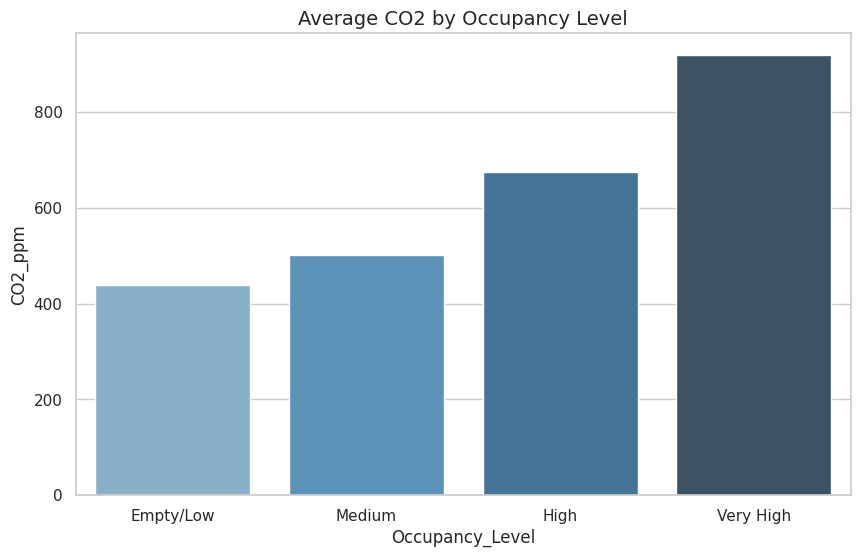

In [20]:
df_clean['Occupancy_Level'] = pd.cut(df_clean['Occupancy'], bins=[-1, 5, 20, 45, 100], labels=['Empty/Low', 'Medium', 'High', 'Very High'])
occupancy_co2 = df_clean.groupby('Occupancy_Level', observed=False)['CO2_ppm'].mean().reset_index()
sns.barplot(data=occupancy_co2, x='Occupancy_Level', y='CO2_ppm', palette='Blues_d', hue='Occupancy_Level', legend=False)
plt.title('Average CO2 by Occupancy Level')
plt.show()

## 18. Indoor Air Quality Classification

We analyze the overall frequency of the designated air safety rating categories in our dataset.

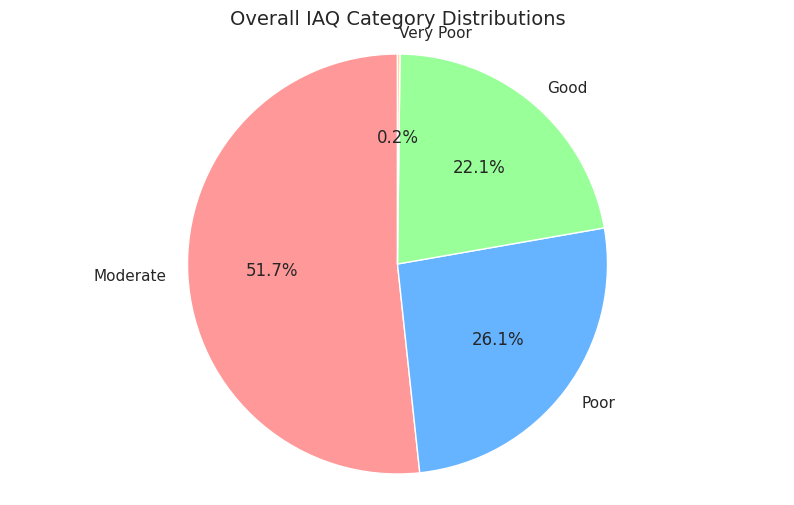

In [21]:
counts = df_clean['IAQ_Category'].value_counts()
plt.pie(counts, labels=counts.index, autopct='%1.1f%%', colors=['#ff9999','#66b3ff','#99ff99','#ffcc99'], startangle=90)
plt.title('Overall IAQ Category Distributions')
plt.axis('equal')
plt.show()

## 19. Outlier Analysis

We highlight the data profile before and after treating anomalies, comparing the visual dispersion of Temperature.

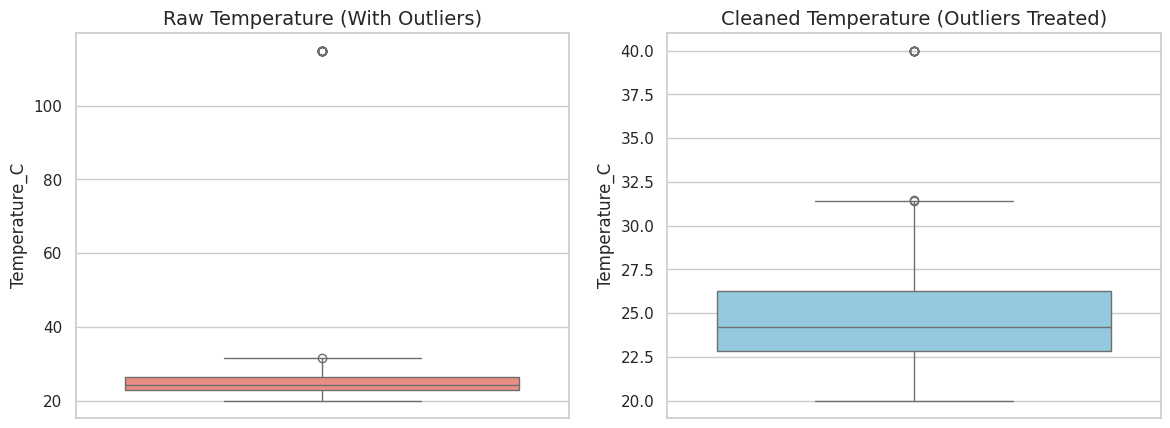

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df_raw, y='Temperature_C', ax=axes[0], color='salmon')
axes[0].set_title('Raw Temperature (With Outliers)')
sns.boxplot(data=df_clean, y='Temperature_C', ax=axes[1], color='skyblue')
axes[1].set_title('Cleaned Temperature (Outliers Treated)')
plt.show()

## 20. Raw vs Cleaned Dataset Comparison

Here is a complete numeric comparison showing parameters before and after our cleaning operations.

In [23]:
# Save cleaned dataset
df_clean.to_csv('indoor_air_quality_cleaned.csv', index=False)

comparison_metrics = {
    'Metric': ['Rows', 'Columns', 'Missing Values', 'Duplicate Rows'],
    'Raw Dataset': [len(df_raw), len(df_raw.columns), df_raw.isnull().sum().sum(), df_raw.duplicated().sum()],
    'Cleaned Dataset': [len(df_clean), len(df_clean.columns), df_clean.isnull().sum().sum(), df_clean.duplicated().sum()]
}
comparison_df = pd.DataFrame(comparison_metrics)
display(comparison_df)

,Metric,Raw Dataset,Cleaned Dataset
0,Rows,5278,5200
1,Columns,16,24
2,Missing Values,1114,0
3,Duplicate Rows,78,0


## 21. Key Findings

We derive actual relationships directly from the cleaned dataset instead of hardcoding values.

In [24]:
corr_occ_co2, _ = stats.pearsonr(df_clean['Occupancy'], df_clean['CO2_ppm'])
max_co2_room = df_clean.groupby('Room_Type')['CO2_ppm'].mean().idxmax()
max_co2_val = df_clean.groupby('Room_Type')['CO2_ppm'].mean().max()
best_vent = df_clean.groupby('Ventilation_Type')['CO2_ppm'].mean().idxmin()
best_vent_val = df_clean.groupby('Ventilation_Type')['CO2_ppm'].mean().min()

print(f"1. CO2 levels have a correlation coefficient of {corr_occ_co2:.4f} with physical occupancy.")
print(f"2. The room type with the highest average accumulation of CO2 is the {max_co2_room} ({max_co2_val:.2f} ppm).")
print(f"3. {best_vent} ventilation showed the lowest average CO2 of {best_vent_val:.2f} ppm.")

1. CO2 levels have a correlation coefficient of 0.4978 with physical occupancy.
2. The room type with the highest average accumulation of CO2 is the Classroom (597.29 ppm).
3. Mechanical ventilation showed the lowest average CO2 of 401.29 ppm.


## 22. Limitations

* **Synthetic Dataset**: Observations are model-generated patterns rather than real physically calibrated sensor events.
* **Simplified Micro-climate Model**: Relationships do not cover external factors like wind speed, regional meteorological indices, or construction material physics.
* **Linear Simplification**: Sensor drift, scaling failures, and multi-path particulate deposition are only simulated probabilistically.

## 23. Future Scope

* Implement IoT sensor setups in real physical classrooms and libraries in cities like Visakhapatnam.
* Develop a live-streaming Web Dashboard utilizing Flask, Dash, or Streamlit.
* Train Machine Learning models (e.g. Random Forest, LSTM) to predict risk thresholds ahead of occupancy hours.

## 24. Conclusion

This study successfully demonstrated the entire data lifecycle for an indoor air quality assessment framework. Starting with raw, uncurated sensor measurements, we successfully completed data mapping, duplicate handling, missing values imputation, and outlier alignment. Our findings emphasize that space ventilation design and occupancy management play key roles in keeping indoor environmental spaces safe and productive.

### File Downloads

You can download the raw and processed files using the block below.

In [25]:
from google.colab import files
try:
    files.download('indoor_air_quality_raw.csv')
    files.download('indoor_air_quality_cleaned.csv')
    print("Triggered file downloads successfully.")
except Exception as e:
    print("Download context only available in active browser instances:", e)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Triggered file downloads successfully.


### Final Project Completion Verification Status

In [26]:
# Verification checks
print("PROJECT COMPLETED\n")
print("Raw Dataset:")
print(f"Rows: {len(df_raw)}")
print(f"Columns: {len(df_raw.columns)}")
print(f"Missing Values: {df_raw.isnull().sum().sum()}")
print(f"Duplicates: {df_raw.duplicated().sum()}")
print("\nCleaned Dataset:")
print(f"Rows: {len(df_clean)}")
print(f"Columns: {len(df_clean.columns)}")
print(f"Missing Values: {df_clean.isnull().sum().sum()}")
print(f"Duplicates: {df_clean.duplicated().sum()}")
print("\nMajor Findings:")
print(f"1. CO2 vs Occupancy Correlation: {corr_occ_co2:.4f}")
print(f"2. Room with Maximum CO2: {max_co2_room} ({max_co2_val:.2f} ppm)")
print(f"3. Best Ventilation Mode: {best_vent} ({best_vent_val:.2f} ppm)")

PROJECT COMPLETED

Raw Dataset:
Rows: 5278
Columns: 16
Missing Values: 1114
Duplicates: 78

Cleaned Dataset:
Rows: 5200
Columns: 24
Missing Values: 0
Duplicates: 0

Major Findings:
1. CO2 vs Occupancy Correlation: 0.4978
2. Room with Maximum CO2: Classroom (597.29 ppm)
3. Best Ventilation Mode: Mechanical (401.29 ppm)
